# Fashion-MNIST — 10 Specialist ResNet-18, Pareto Exploration & Expansion, lalu Generalist

Jalankan sel **berurutan**. Setiap kelas (0–9) mempunyai Specialist ResNet-18 one-vs-rest dan menjalani **PCGrad, MGDA, FAMO**, dilanjutkan **MINRES** serta **Alfa tengah** pada pasangan kandidatnya. Teacher setiap kelas dipilih **hanya dari loss validasi** (minimax dua objektif), lalu kesepuluh teacher dipakai untuk target lunak Generalist.

**Sumbu grafik Specialist:** X = BCE mendeteksi kelas tersebut, Y = BCE mendeteksi *bukan* kelas tersebut, keduanya dihitung pada seluruh sampel validasi. Grafik tiga metode dipisah dan memakai batas sumbu X/Y yang sama **di dalam kelas yang sama**. Titik lintasan training **bukan otomatis Pareto front**.

**Biaya komputasi:** setiap Specialist menjalani tiga pelatihan ResNet-18 penuh; MINRES menggunakan Hessian-vector product. Proses ini sangat berat meskipun VRAM 32 GB. `SECONDS` diperiksa hanya di antara ronde MINRES, bukan ketika solver sedang berjalan. Butuh PyTorch, torchvision, NumPy, Matplotlib, SciPy, dan Fashion-MNIST (`download=True` pada pemakaian pertama).

In [1]:
# math menyediakan ceil dan log, random mengacak pergeseran dan urutan PCGrad, time mengukur durasi.
import math, random, time
# np mengolah array gambar dan label. torch menyediakan tensor, perangkat komputasi, dan gradien.
import numpy as np
import torch
# nn menyediakan lapisan jaringan. F menyediakan operasi padding, fungsi loss, dan softmax.
import torch.nn as nn
import torch.nn.functional as F
# plt menggambar hasil. datasets memuat Fashion-MNIST dan models menyediakan arsitektur ResNet.
import matplotlib.pyplot as plt
from torchvision import datasets, models

In [2]:
from copy import deepcopy
from collections import deque
from scipy.sparse.linalg import LinearOperator, minres
import inspect

In [3]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Perangkat:', dev)

Perangkat: cuda


In [4]:
# Semua 10 kelas diproses berurutan; tidak ada lagi kelas tunggal CFG['CLASS'].
CFG = dict(
    SEED=0, BS=128, LR=0.001, EPOCHS=4, N_SPEC_HARD=2000,
    STEPS=60, ROUNDS=8, TARGET=0.15, WIDTH=0.02, PATIENCE=3,
    ALPHA_WINDOW=8, SECONDS=180, MINRES_ITERS=24,
    MINRES_BS=8,  # HVP memakai batch kecil agar lebih realistis untuk ResNet-18
    DAMP=0.1, STEP_SIZE=0.05,
    PLOT_SPECIALISTS=True,
    SAVE_TEACHERS=True,  # simpan satu checkpoint pemenang per kelas (bukan semua epoch)
    TEACHER_DIR='fashion_resnet18_teachers'
)


In [5]:
# set_seed menerima s dari SEED (ditambah indeks kelas untuk spesialis). Fungsi mengatur generator
# acak Python, NumPy dan PyTorch tanpa nilai balik.
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

## Data spesialis
Data latih mencakup gambar tunggal serta potongan pakaian dari tumpukan. Validasi memilih model. Data uji hanya dipakai setelah pilihan selesai.

In [6]:
# CANVAS dan DS adalah ukuran sisi kanvas dan pakaian dalam piksel untuk penempatan, crop, padding, dan prep.
CANVAS, DS = 56, 28           # kanvas diperluas (sebelumnya 36), digit tetap 28x28 asli
# MAX_OVERLAP menjadi sasaran batas tumpang tindih saat mencari posisi di make_multi_flexible.
MAX_OVERLAP = 0.25            # maks. overlap kotak antar pakaian (fraksi luas 28x28)
# K_MIN dan K_MAX menentukan rentang jumlah pakaian per kanvas. K_MAX juga menentukan banyak slot label dan posisi.
K_MIN, K_MAX = 2, 4
# CLASS_NAMES memetakan indeks label Fashion-MNIST ke nama untuk laporan dan judul grafik.
CLASS_NAMES = ('T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot')

In [7]:
# fashion_tr dan fashion_te adalah dataset asli dari torchvision. Atribut data dan targets dibaca di bawah.
fashion_tr = datasets.FashionMNIST('./data', train=True, download=True)
fashion_te = datasets.FashionMNIST('./data', train=False, download=True)
# all_tr_x/all_tr_y menyimpan gambar/label untuk pembagian latih-validasi. fa_te_x/fa_te_y untuk tumpukan dan evaluasi uji.
all_tr_x, all_tr_y = fashion_tr.data.numpy(), fashion_tr.targets.numpy()
fa_te_x, fa_te_y = fashion_te.data.numpy(), fashion_te.targets.numpy()

100%|██████████| 29.5k/29.5k [00:00<00:00, 181kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]


In [8]:
# perm adalah urutan indeks acak dari SEED. Indeks yang sama menjaga pasangan gambar dan label saat dibagi.
perm = np.random.RandomState(CFG['SEED']).permutation(len(all_tr_x))
# fa_tr_x/fa_tr_y berisi 54.000 pasangan latih untuk gambar tunggal dan pembuatan tumpukan.
fa_tr_x, fa_tr_y = all_tr_x[perm[:54000]], all_tr_y[perm[:54000]]
# fa_val_x/fa_val_y adalah sisa pasangan dari perm untuk membuat tumpukan validasi.
fa_val_x, fa_val_y = all_tr_x[perm[54000:]], all_tr_y[perm[54000:]]

In [9]:
# make_multi_flexible membuat n kanvas dari imgs dan labels milik bagian data yang dipilih pemanggil.
# k_min/k_max membatasi jumlah item, seed mengatur undian, max_overlap dan n_tries mengatur pencarian posisi.
# Hasilnya tiga array NumPy berurutan (gambar, ID kelas per slot, koordinat per slot), diterima keluarga Xg/Yg/Pg atau Xh_raw/Yh_raw/Ph_raw.
def make_multi_flexible(imgs, labels, n, k_min=K_MIN, k_max=K_MAX, seed=1,
                        max_overlap=MAX_OVERLAP, n_tries=30):
    # rng adalah generator lokal dari seed untuk mengundi jumlah, indeks, dan posisi pakaian.
    rng = np.random.RandomState(seed)
    # X menyimpan piksel tiap kanvas. Y menyimpan ID kelas dan P menyimpan (baris, kolom) tiap slot.
    # -1 menandai slot kosong.
    X = np.zeros((n, CANVAS, CANVAS), dtype=np.uint8)
    Y = np.full((n, k_max), -1, dtype=np.int64)
    P = np.full((n, k_max, 2), -1, dtype=np.int64)
    # off adalah koordinat awal terbesar agar pakaian tetap muat di kanvas.
    off = CANVAS - DS
    # i memilih kanvas keluaran. k_items adalah jumlah pakaian yang diundi untuk kanvas itu.
    for i in range(n):
        k_items = rng.randint(k_min, k_max + 1)
        # idx berisi indeks sumber dari imgs/labels. boxes mengingat posisi yang sudah ditempati pada kanvas i.
        idx = rng.randint(0, len(imgs), size=k_items)
        boxes = []
        # k adalah nomor slot keluaran, j indeks gambar asli dari idx untuk mengisi slot k.
        for k, j in enumerate(idx):
            # best dan best_ov menyimpan posisi dengan overlap terkecil beserta nilainya selama pencarian.
            best, best_ov = None, 9.0
            # _ menghitung percobaan sampai n_tries. py dan px adalah calon baris dan kolom kiri atas.
            for _ in range(n_tries):          # cari posisi dengan overlap kecil
                py, px = rng.randint(0, off + 1), rng.randint(0, off + 1)
                # by dan bx berasal dari boxes. ov adalah fraksi overlap terbesar calon posisi terhadap pakaian sebelumnya.
                ov = max([max(0, DS - abs(py - by)) * max(0, DS - abs(px - bx)) / (DS * DS)
                          for by,bx in boxes], default=0.0)
                if ov < best_ov:
                    best, best_ov = (py,px), ov
                if ov <= max_overlap:
                    break
            # py dan px mengambil posisi terbaik yang ditemukan, termasuk bila batas overlap belum tercapai.
            py, px = best
            boxes.append((py, px))
            # patch menjumlahkan piksel lama dan imgs[j] dalam 16 bit. Hasil dibatasi ke 255 untuk X,
            # lalu label dan posisi dicatat.
            patch = X[i, py:py+DS, px:px+DS].astype(np.uint16) + imgs[j].astype(np.uint16)
            X[i, py:py+DS, px:px+DS] = np.minimum(patch, 255).astype(np.uint8)
            Y[i, k] = labels[j]
            P[i, k] = [py, px]
    return X, Y, P

In [10]:
# crop_pad menerima kanvas X, posisi P, dan nomor slot k dari pembuat data spesialis atau teacher_presence.
# Hasilnya array seukuran X berisi crop slot k di tengah kanvas hitam. Slot kosong menghasilkan kanvas hitam.
def crop_pad(X, P, k):
    # out menampung hasil crop. o adalah offset untuk menempatkannya di tengah.
    out = np.zeros_like(X)
    o = (CANVAS - DS) // 2
    # i memilih kanvas. y dan x berasal dari P[i,k] untuk menentukan area piksel sumber.
    for i in range(len(X)):
        if P[i, k, 0] != -1:
            y, x = P[i, k]
            out[i, o:o+DS, o:o+DS] = X[i, y:y+DS, x:x+DS]
    return out

In [11]:
# pad_fashion menerima imgs dari fa_tr_x atau fa_te_x dan mengembalikan kanvas terpusat untuk Xs atau Xte_single.
def pad_fashion(imgs):
    # out adalah kanvas kosong per gambar, o adalah offset tempat menyalin imgs ke tengah.
    out = np.zeros((len(imgs), CANVAS, CANVAS), np.uint8)
    o = (CANVAS - DS) // 2
    out[:, o:o+DS, o:o+DS] = imgs
    return out

In [12]:
# Data spesialis: gambar tunggal bersih + crop dari tumpukan, semuanya berlabel ASLI
# n_h menghitung jumlah kanvas sumber crop dari batas N_SPEC_HARD dan jumlah slot maksimum.
n_h = (CFG['N_SPEC_HARD'] + K_MAX - 1) // K_MAX
# Xh_raw/Yh_raw/Ph_raw adalah kanvas, kelas, dan posisi sintetis dari data latih untuk membuat contoh spesialis.
Xh_raw, Yh_raw, Ph_raw = make_multi_flexible(fa_tr_x, fa_tr_y, n_h, seed=4)
# Xs_h/Ys_h mula-mula daftar kumpulan crop/label per slot. k memilih slot, v menandai gambar yang memiliki slot itu.
Xs_h, Ys_h = [], []
for k in range(K_MAX):
    v = Ph_raw[:, k, 0] != -1
    Xs_h.append(crop_pad(Xh_raw, Ph_raw, k)[v]); 
    Ys_h.append(Yh_raw[v, k])
# Xs_h dan Ys_h kemudian menjadi array crop dan label yang digabung, dipotong sesuai batas, lalu dipasangkan dengan data bersih.
Xs_h = np.concatenate(Xs_h)[:CFG['N_SPEC_HARD']]
Ys_h = np.concatenate(Ys_h)[:CFG['N_SPEC_HARD']]
# Xs memasangkan kanvas bersih dan crop dalam satu array gambar. Ys menyusun label asli dalam urutan yang sama.
Xs = np.concatenate([pad_fashion(fa_tr_x), Xs_h])
Ys = np.concatenate([fa_tr_y, Ys_h])

In [13]:
# Tensor disimpan di CPU. Hanya batch yang sedang diproses dipindahkan ke dev.
train = torch.from_numpy(Xs), torch.from_numpy(Ys)
valid = torch.from_numpy(pad_fashion(fa_val_x)), torch.from_numpy(fa_val_y)
test = torch.from_numpy(pad_fashion(fa_te_x)), torch.from_numpy(fa_te_y)
for c in range(len(CLASS_NAMES)):
    print('Spesialis:', CLASS_NAMES[c], '| Total gbr latih:', len(Ys), '| gbr kelas target:', np.sum(Ys == c), '| gbr kelas lainnya:', np.sum(Ys != c))


Spesialis: T-shirt/top | Total gbr latih: 55476 | gbr kelas target: 5518 | gbr kelas lainnya: 49958
Spesialis: Trouser | Total gbr latih: 55476 | gbr kelas target: 5556 | gbr kelas lainnya: 49920
Spesialis: Pullover | Total gbr latih: 55476 | gbr kelas target: 5561 | gbr kelas lainnya: 49915
Spesialis: Dress | Total gbr latih: 55476 | gbr kelas target: 5582 | gbr kelas lainnya: 49894
Spesialis: Coat | Total gbr latih: 55476 | gbr kelas target: 5541 | gbr kelas lainnya: 49935
Spesialis: Sandal | Total gbr latih: 55476 | gbr kelas target: 5555 | gbr kelas lainnya: 49921
Spesialis: Shirt | Total gbr latih: 55476 | gbr kelas target: 5533 | gbr kelas lainnya: 49943
Spesialis: Sneaker | Total gbr latih: 55476 | gbr kelas target: 5558 | gbr kelas lainnya: 49918
Spesialis: Bag | Total gbr latih: 55476 | gbr kelas target: 5528 | gbr kelas lainnya: 49948
Spesialis: Ankle boot | Total gbr latih: 55476 | gbr kelas target: 5544 | gbr kelas lainnya: 49932


In [14]:
# 1 fungsiprep() menyiapkan gambar sebelum dimasukkan ke model. 
# 1 Gambar diubah ke format yang bisa dibaca model, lalu bisa digeser sedikit secara acak.
# 2 xb atau x-batch adalah sekumpulan gambar dalam bentuk tensor. 
# 2 Pada notebook ini, ukurannya (jumlah gambar, 56, 56). Setiap piksel biasanya bernilai dari 0 sampai 255.
# 3 shift adalah batas pergeseran acak dalam satuan piksel. Nilai awalnya 0, yang berarti gambar tidak digeser.   
# 4 Outputnya adalah tensor x yang siap masuk ke model. Ukurannya menjadi (jumlah gambar, 1, 56, 56). 
# 4 Angka 1 menunjukkan satu kanal warna karena gambar berwarna abu-abu. Nilai pikselnya sudah berada dalam rentang 0 sampai 1.
def prep(xb, shift=0): 
    # x berasal dari xb, dikonversi ke .float(), bagi .div(255), .unsqueeze(1) menambahkan dimensi kanal pada posisi ke-1
    x = xb.float().div(255).unsqueeze(1)
    if shift: 
        # sy dan sx adalah pergeseran acak vertikal/horizontal untuk seluruh batch. x dipad lalu dipotong kembali seukuran CANVAS.
        sy, sx = random.randint(-shift, shift), random.randint(-shift, shift) # cari int buat digeser
        x = F.pad(x, (shift,)*4) # padding biar ga kepotong pas digeser
        x = x[:, :, shift+sy:shift+sy+CANVAS, shift+sx:shift+sx+CANVAS] # baru deh dipotong
    return x # satu x-batch yang sudah digeser random sejauh shift

## Arsitektur ResNet-18 dan dua objective
Backbone ResNet-18 grayscale (1×56×56) menghasilkan 32 fitur dan dua head independen. Loss setiap Specialist adalah **kelas target (`class_id`)** dan **bukan kelas target**. `class_id` wajib diberikan untuk label 1D agar tidak diam-diam memakai satu kelas global. Untuk Generalist, label 2D berarti 10 target kehadiran kelas dan diringkas menjadi dua loss global.

In [15]:

class Specialist(nn.Module):
    def __init__(self):
        super().__init__()

        # ResNet-18 tanpa pretrained weights.
        # Tidak perlu mengunduh bobot model.
        resnet = models.resnet18(weights=None)

        # Fashion-MNIST grayscale: 1 channel, bukan RGB.
        # Kernel 3x3 dan stride 1 lebih sesuai untuk 56x56.
        resnet.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        # Hindari downsampling terlalu dini pada gambar kecil.
        resnet.maxpool = nn.Identity()

        # Ganti classifier bawaan menjadi 32 fitur,
        # agar tetap kompatibel dengan Generalist.
        in_features = resnet.fc.in_features
        resnet.fc = nn.Linear(in_features, 32)

        # Backbone tetap berupa satu modul bersama.
        self.backbone = resnet

        # Pertahankan dua head seperti arsitektur asli.
        self.heads = nn.ModuleList([
            nn.Linear(32, 1),
            nn.Linear(32, 1)
        ])

    def forward(self, x):
        features = self.backbone(x)

        return torch.cat(
            [head(features) for head in self.heads],
            dim=1
        )



In [16]:
def head_losses(model, batch, class_id=None):
    """Kembalikan [loss_hadir, loss_tidak_hadir] untuk Specialist/Generalis."""
    images, labels = batch
    scores = model(prep(images.to(dev)))
    if labels.ndim == 2:
        # Generalist: target soft/hard (B, 10) -> (B, 10, 2)
        present = labels.to(device=dev, dtype=scores.dtype)
        targets = torch.stack([present, 1.0 - present], dim=2)
        return F.binary_cross_entropy_with_logits(
            scores, targets, reduction='none'
        ).mean((0, 1))

    if class_id is None:
        raise ValueError('Specialist membutuhkan class_id eksplisit (0..9).')
    positive = labels.to(dev) == int(class_id)
    targets = torch.stack([positive, ~positive], dim=1).to(scores.dtype)
    return F.binary_cross_entropy_with_logits(
        scores, targets, reduction='none'
    ).mean(dim=0)


In [17]:
@torch.no_grad()
def evaluate(model, data, class_id=None):
    """Loss rata-rata tertimbang ukuran batch; pulihkan mode model usai evaluasi."""
    previous_mode = model.training
    model.eval()  # BatchNorm ResNet-18 memakai running statistics, tidak mengubahnya
    try:
        total = torch.zeros(2, device=dev)
        for images, labels in zip(*(v.split(CFG['BS']) for v in data)):
            total += len(labels) * head_losses(model, (images, labels), class_id)
        return (total / len(data[1])).cpu().numpy()
    finally:
        model.train(previous_mode)


In [18]:
def flat_grads(losses, params):
    """Matriks gradien: satu baris per objektif, satu kolom per parameter."""
    params = tuple(params)  # aman jika pemanggil mengirim generator .parameters()
    gs = []
    for loss in losses:
        grads = torch.autograd.grad(
            loss, params, retain_graph=True, allow_unused=True
        )
        gs.append(torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(grads, params)
        ]))
    return torch.stack(gs, dim=0)


In [19]:
# pcgrad menerima matriks gradien G dari flat_grads. Hasilnya vektor jumlah gradien setelah proyeksi, untuk g di train_step.
def pcgrad(G):
    # T adalah jumlah baris G. out menyalin G agar tiap baris dapat diperbarui.
    T = len(G); out = G.clone()
    # i memilih tugas yang dikoreksi, j memilih tugas pembanding secara acak.
    for i in range(T):
        for j in random.sample(range(T), T):
            if j == i: continue
            # dot mengukur keselarasan out[i] dan G[j]. Nilai negatif memicu pengurangan komponen yang bertentangan.
            dot = (out[i] * G[j]).sum()
            if dot < 0:
                out[i] = out[i] - dot / (G[j].norm() ** 2 + 1e-12) * G[j]
    return out.sum(0)

In [20]:
# mgda_weights menerima G dari flat_grads dan batas iterasi iters. Hasilnya bobot a untuk kombinasi gradien a @ G.
def mgda_weights(G, iters=50):
    # M berisi hasil kali dalam antargradien. T jumlah tugas untuk menentukan ukuran a.
    M = G @ G.T; T = len(G)
    # a dimulai dengan bobot seragam, lalu diperbarui untuk memperkecil norma gradien gabungan.
    a = torch.ones(T, device=G.device) / T
    # _ menghitung iterasi. i memilih komponen terkecil dari M @ a sebagai arah menuju satu tugas.
    for _ in range(iters):
        i = torch.argmin(M @ a)
        # e memberi bobot satu pada tugas i. d adalah perubahan dari a menuju e, gamma menentukan panjang langkah sepanjang d.
        e = torch.zeros_like(a); 
        e[i] = 1
        d = e - a
        gamma = torch.clamp(-(d @ M @ a) / (d @ M @ d + 1e-12), 0, 1)
        a = a + gamma * d
    return a

In [21]:
# FAMO menyimpan dan menyesuaikan bobot tugas selama pelatihan bila METHOD memilih famo.
class FAMO:
    # __init__ menerima self, jumlah tugas T dari train_step, lr untuk Adam internal dan gamma untuk weight decay. Ia mengisi atribut instance.
    def __init__(self, T, lr=0.025, gamma=1e-3):
        # self.w adalah skor bobot yang dilatih. self.opt mengoptimalkan skor ini dan self.eps menjaga log dan pembagian tetap terdefinisi.
        self.w = torch.zeros(T, device=dev, requires_grad=True)
        self.opt = torch.optim.Adam([self.w], lr=lr, weight_decay=gamma)
        self.eps = 1e-8
    # weighted menerima self dan tensor losses hasil stack loss tiap tugas. Hasilnya loss skalar untuk backward di train_step.
    def weighted(self, losses):
        # D adalah losses ditambah eps, z adalah bobot tugas ternormalisasi dari self.w, c adalah faktor normalisasi tanpa gradien.
        D = losses + self.eps
        z = F.softmax(self.w, -1)
        c = (z / D).sum().detach()
        return (D.log() * z / c).sum()
    # update menerima self, prev dan curr (loss per tugas sebelum dan sesudah langkah model). Ia memperbarui self.w tanpa nilai balik.
    def update(self, prev, curr):
        # delta mengukur penurunan log-loss per tugas. d mengubah delta menjadi gradien untuk self.w.grad yang dipakai self.opt.
        delta = (prev + self.eps).log() - (curr + self.eps).log()
        with torch.enable_grad():
            d = torch.autograd.grad(F.softmax(self.w, -1), self.w, grad_outputs=delta.detach())[0]
        self.opt.zero_grad(); self.w.grad = d; self.opt.step()

In [22]:
def train_step(model, optimizer, batch, method, famo=None, alpha=None, class_id=None):
    """Satu optimizer step dengan dua objective; class_id untuk Specialist."""
    model.train()
    losses = head_losses(model, batch, class_id=class_id)
    optimizer.zero_grad()

    if method in ('MGDA', 'PCGrad'):
        shared = list(model.backbone.parameters())
        G = flat_grads(losses, shared)
        if method == 'MGDA':
            alpha = mgda_weights(G).detach()
            combined = alpha @ G
        else:
            combined = pcgrad(G) / len(losses)
        # Head diperbarui dari rata-rata loss; backbone dari PCGrad/MGDA.
        losses.mean().backward()
        offset = 0
        for param in shared:
            size = param.numel()
            param.grad = combined[offset:offset + size].view_as(param).clone()
            offset += size
    elif method == 'FAMO':
        if famo is None:
            raise ValueError('Metode FAMO membutuhkan state FAMO.')
        alpha = famo.w.detach().softmax(0)
        famo.weighted(losses).backward()
        # Mengukur before/after dalam mode eval mencegah dua pembaruan BatchNorm.
        model.eval()
        with torch.no_grad():
            before = head_losses(model, batch, class_id=class_id)
    else:
        if alpha is None:
            raise ValueError('Alfa tengah membutuhkan bobot alpha.')
        (alpha @ losses).backward()

    optimizer.step()
    if method == 'FAMO':
        with torch.no_grad():
            after = head_losses(model, batch, class_id=class_id)
        famo.update(before, after)
        model.train()
    return None if alpha is None else alpha.detach().cpu().numpy()


In [23]:
def checkpoint(model, name, alpha=None, valid=valid, class_id=None):
    """Satu snapshot CPU + dua loss validasi; tanpa data uji untuk pemilihan."""
    xy = evaluate(model, valid, class_id=class_id)
    alpha_copy = None if alpha is None else np.asarray(alpha, dtype=np.float32).copy()
    return dict(
        name=name, xy=xy, score=float(max(xy)), alpha=alpha_copy,
        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    )


In [ ]:
def explore(initial, method, train=train, valid=valid, class_id=None):
    """Training dari bobot awal identik antar-metode untuk satu kelas."""
    seed = CFG['SEED'] + (class_id if class_id is not None else 0)
    set_seed(seed)
    model = deepcopy(initial)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    famo = FAMO(2) if method == 'FAMO' else None
    history = []
    for epoch in range(CFG['EPOCHS']):
        epoch_start = time.perf_counter()
        recent = deque(maxlen=CFG['ALPHA_WINDOW'])

        batches = torch.randperm(
            len(train[1])
        ).split(CFG['BS'])

        print(
            f"[{CLASS_NAMES[class_id]}] "
            f"{method} | Epoch {epoch+1}/{CFG['EPOCHS']} "
            f"| {len(batches)} batch",
            flush=True
        )

        for batch_no, ids in enumerate(batches, 1):
            alpha = train_step(
                model, optimizer,
                (train[0][ids], train[1][ids]),
                method, famo=famo, class_id=class_id
            )

            if alpha is not None:
                recent.append(alpha)

            if batch_no % 50 == 0 or batch_no == len(batches):
                print(
                    f"  Batch {batch_no}/{len(batches)} "
                    f"| {time.perf_counter()-epoch_start:.1f}s",
                    flush=True
                )

        history.append(checkpoint(
            model, method,
            np.mean(recent, axis=0) if recent else None,
            valid=valid, class_id=class_id
        ))
    return history


In [25]:
def plot_exploration(class_id, start, paths):
    """Tiga panel terpisah; skala X/Y sama untuk perbandingan intra-kelas."""
    methods = ('FAMO', 'MGDA', 'PCGrad')
    all_xy = np.vstack([
        np.array([p['xy'] for p in [start] + paths[m]]) for m in methods
    ])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    dx = max(xmax - xmin, 1e-4) * 0.06
    dy = max(ymax - ymin, 1e-4) * 0.06
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
    for ax, method in zip(axes, methods):
        xy = np.array([p['xy'] for p in [start] + paths[method]])
        ax.plot(xy[:, 0], xy[:, 1], 'o-', label=method)
        ax.scatter(*start['xy'], marker='*', s=180, color='black', zorder=5, label='Awal')
        for epoch, pt in enumerate(xy):
            ax.annotate('Awal' if epoch == 0 else f'E{epoch}', pt,
                        xytext=(6, 6), textcoords='offset points', fontsize=9)
        ax.set(xlim=(xmin-dx, xmax+dx), ylim=(ymin-dy, ymax+dy),
               title=method, xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Exploration Specialist {class_id}: {CLASS_NAMES[class_id]}', fontsize=14)
    plt.tight_layout()
    plt.show()


## Menentukan dua kandidat untuk Pareto Expansion
Prioritas adalah **pasangan FAMO–MGDA yang tidak terdominasi** dan punya trade-off dua loss serta beda alpha yang cukup. Karena tidak setiap kelas menghasilkan pasangan itu, tersedia **fallback** dari checkpoint FAMO/MGDA; fallback **tidak boleh disebut Pareto front** jika terdominasi. Semua kelas dicoba, tetapi MINRES dapat gagal secara numerik dan perlu dilaporkan apa adanya.

In [26]:
def dominates(a, b):
    # A mengalahkan B bila kedua loss paling tidak sama baik, dan minimal satu lebih kecil.
    return np.all(a['xy'] <= b['xy']) and np.any(a['xy'] < b['xy'])

In [27]:
def choose_pair(points, allow_fallback=False):
    """Cari pasangan FAMO/MGDA; fallback dipakai pada 10 Specialist bila perlu."""
    front = [p for p in points if not any(dominates(q, p) for q in points)]
    eligible = sorted(
        (p for p in front if p['name'] in ('FAMO', 'MGDA') and p['alpha'] is not None),
        key=lambda p: p['xy'][0]
    )
    pairs = [
        (a, b) for a, b in zip(eligible, eligible[1:])
        if a['name'] != b['name'] and a['xy'][0] < b['xy'][0]
        and a['xy'][1] > b['xy'][1]
        and abs(float(a['alpha'][0] - b['alpha'][0])) > CFG['WIDTH']
    ]
    if pairs:
        return max(pairs, key=lambda ab: np.linalg.norm(ab[0]['xy'] - ab[1]['xy']))
    if not allow_fallback:
        return None

    # Tetap lakukan upaya expansion per kelas bila Pareto pair ketat tidak muncul.
    candidates = [p for p in points if p['name'] in ('MGDA', 'FAMO') and p['alpha'] is not None]
    fallbacks = [
        (a, b) for a in candidates for b in candidates
        if a['name'] == 'FAMO' and b['name'] == 'MGDA'
    ]
    if not fallbacks:
        return None
    # Prioritaskan perbedaan alpha, kemudian pemisahan titik di ruang loss.
    return max(fallbacks, key=lambda ab: (
        abs(float(ab[0]['alpha'][0] - ab[1]['alpha'][0])),
        float(np.linalg.norm(ab[0]['xy'] - ab[1]['xy']))
    ))


## Pareto Expansion: MINRES dan Alfa tengah
Kedua strategi bekerja pada pasangan checkpoint hasil exploration. MINRES mencoba arah lokal berdasarkan Hessian-vector product; Alfa tengah melatih model menggunakan bobot dua objektif yang dirata-ratakan. Untuk ResNet-18, ukuran batch MINRES dipisah dari batch training (`MINRES_BS`). Solver MINRES tetap bisa lama atau gagal karena numerik; jika gagal, teacher tetap dipilih dari kandidat exploration/expansion valid yang tersedia. Timeout diperiksa **antar-ronde**, bukan menghentikan satu solver yang sedang aktif.

In [28]:
def midpoint_candidate(model, left, right, round_id, rng,
                       train=train, valid=valid, class_id=None):
    parent = (left, right)[round_id % 2]
    model.load_state_dict(parent['state'])
    alpha = (left['alpha'] + right['alpha']) / 2
    weight = torch.as_tensor(alpha, device=dev, dtype=torch.float32)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    for step in range(CFG['STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        train_step(model, optimizer, (train[0][ids], train[1][ids]),
                   'Alfa tengah', alpha=weight, class_id=class_id)
    return checkpoint(model, 'Alfa tengah', alpha, valid=valid, class_id=class_id)


In [29]:
def minres_candidate(model, left, right, round_id, rng,
                     train=train, valid=valid, class_id=None):
    """Hessian-vector product penuh; batch kecil dan mode eval untuk BatchNorm."""
    parent, other = (left, right) if round_id % 2 == 0 else (right, left)
    model.load_state_dict(parent['state'])
    model.eval()
    bs = min(CFG['MINRES_BS'], len(train[1]))
    ids = torch.randint(len(train[1]), (bs,), generator=rng)
    losses = head_losses(model, (train[0][ids], train[1][ids]), class_id=class_id)
    params = list(model.parameters())
    G = flat_grads(losses, params).detach()
    alpha = mgda_weights(G).detach()
    desired = torch.as_tensor(other['alpha'], device=dev, dtype=G.dtype)
    rhs = (-(desired - alpha) @ G).cpu().double().numpy()
    if not np.isfinite(rhs).all() or np.linalg.norm(rhs) < 1e-12:
        print('MINRES: RHS nol/tidak finite; kandidat tidak dibuat')
        return None

    grads = torch.autograd.grad(alpha @ losses, params, create_graph=True)
    gradient = torch.cat([g.reshape(-1) for g in grads])
    # HVP dievaluasi berulang oleh scipy; tidak membentuk Hessian penuh.
    def multiply(vector):
        v = torch.as_tensor(vector, dtype=gradient.dtype, device=dev)
        hv = torch.autograd.grad(
            gradient, params, grad_outputs=v,
            retain_graph=True, allow_unused=True
        )
        result = torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(hv, params)
        ]) + CFG['DAMP'] * v
        return result.detach().cpu().double().numpy()

    operator = LinearOperator((len(rhs), len(rhs)), matvec=multiply, dtype=np.float64)
    tolerance = 'rtol' if 'rtol' in inspect.signature(minres).parameters else 'tol'
    direction, info = minres(
        operator, rhs, maxiter=CFG['MINRES_ITERS'], **{tolerance: 1e-3}
    )
    residual = np.linalg.norm(multiply(direction) - rhs) / max(np.linalg.norm(rhs), 1e-12)
    print('MINRES status:', info, '| residu relatif:', round(float(residual), 4))
    if info < 0 or not np.isfinite(residual) or residual >= 1 or np.linalg.norm(direction) < 1e-12:
        return None

    delta = torch.as_tensor(direction, device=dev, dtype=gradient.dtype)
    delta *= CFG['STEP_SIZE'] / delta.norm().clamp(min=CFG['STEP_SIZE'])
    offset = 0
    with torch.no_grad():
        for param in params:
            param.add_(delta[offset:offset + param.numel()].view_as(param))
            offset += param.numel()
    return checkpoint(model, 'MINRES', ((alpha + desired) / 2).cpu().numpy(),
                      valid=valid, class_id=class_id)


In [30]:
def run_expand(pair, generate, initial, pool, train=train, valid=valid, class_id=None):
    """Upayakan setidaknya satu ronde per strategi per kelas bila ada pasangan."""
    if pair is None:
        return [], 0., 'Tidak ada pasangan FAMO-MGDA'
    left, right = pair
    model = deepcopy(initial)
    seed = CFG['SEED'] + 1 + (class_id if class_id is not None else 0)
    rng = torch.Generator().manual_seed(seed)
    points = []
    best = min(p['score'] for p in pool)
    stale = 0
    reason = 'Batas ronde'
    begin = time.perf_counter()
    for r in range(CFG['ROUNDS']):
        # Mulai cek early stopping SETELAH upaya ronde pertama.
        if r > 0 and (best <= CFG['TARGET'] or stale >= CFG['PATIENCE']):
            reason = 'Target tercapai' if best <= CFG['TARGET'] else 'Skor belum membaik'
            break
        if r > 0 and time.perf_counter() - begin >= CFG['SECONDS']:
            reason = 'Batas waktu (dicek antar-ronde)'
            break
        if (r > 0 and generate is midpoint_candidate
                and abs(left['alpha'][0] - right['alpha'][0]) <= CFG['WIDTH']):
            reason = 'Interval alfa kecil'
            break
        try:
            new = generate(model, left, right, r, rng, train, valid, class_id=class_id)
        except (RuntimeError, ValueError, FloatingPointError, MemoryError) as err:
            reason = f'Gagal {type(err).__name__}: {str(err)[:180]}'
            print('Peringatan expansion:', reason)
            break
        if new is None:
            reason = 'Langkah numerik gagal'
            break
        points.append(new)
        stale = 0 if new['score'] < best else stale + 1
        best = min(best, new['score'])
        if left['score'] <= right['score']:
            right = new
        else:
            left = new
    return points, time.perf_counter() - begin, reason


In [31]:
def plot_expansion(class_id, pool, pair, results):
    """Dua panel expansion memakai skala sama pada kelas target."""
    all_points = pool + [p for extra, _, _ in results.values() for p in extra]
    all_xy = np.array([p['xy'] for p in all_points])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    xpad = max(xmax - xmin, 1e-4) * 0.06
    ypad = max(ymax - ymin, 1e-4) * 0.06
    fig, panels = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for ax, name in zip(panels, ('MINRES', 'Alfa tengah')):
        ax.scatter(*np.array([p['xy'] for p in pool]).T,
                   color='silver', label='Exploration')
        if pair is not None:
            for label, point in zip(('A', 'B'), pair):
                ax.scatter(*point['xy'], marker='s', zorder=3)
                ax.annotate(label, point['xy'])
        for r, point in enumerate(results[name][0], 1):
            ax.scatter(*point['xy'], color='darkgreen', zorder=4)
            note = f'{r}' if name == 'MINRES' else f"{r}: α={point['alpha'][0]:.2f}"
            ax.annotate(note, point['xy'], xytext=(4, 5), textcoords='offset points')
        ax.set(title=f"{name} ({results[name][2]})",
               xlim=(xmin-xpad, xmax+xpad), ylim=(ymin-ypad, ymax+ypad),
               xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    panels[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Expansion Specialist {class_id}: {CLASS_NAMES[class_id]}')
    plt.tight_layout()
    plt.show()


## Jalankan Pareto Exploration dan Expansion untuk **semua 10 teacher**
Sel ini menjalankan kelas 0–9 **secara berurutan** agar checkpoint antar-kelas tidak menumpuk di RAM. Untuk tiap kelas: inisialisasi ResNet-18 → exploration 3 metode → pilih pasangan → expansion 2 metode → pilih pemenang berdasarkan validasi → evaluasi test setelah pemilihan → simpan teacher. Ringkasan hasil semua kelas tetap disimpan, sedangkan state checkpoint kandidat lain dibebaskan. Jika `SAVE_TEACHERS=True`, satu checkpoint teacher terpilih per kelas juga disimpan ke disk untuk pemulihan.

In [32]:
def run_specialist_class(class_id, train=train, valid=valid, test=test):
    """Seluruh pipeline Pareto per kelas; kembalikan teacher dan ringkasan tanpa state besar."""
    import gc
    from pathlib import Path

    set_seed(CFG['SEED'] + class_id)
    initial = Specialist().to(dev)
    start = checkpoint(initial, 'Awal', valid=valid, class_id=class_id)
    paths = {
        method: explore(initial, method, train=train, valid=valid, class_id=class_id)
        for method in ('PCGrad', 'MGDA', 'FAMO')
    }
    pool = [p for history in paths.values() for p in history]
    pair = choose_pair(pool, allow_fallback=True)
    pair_type = 'tidak tersedia'
    if pair is not None:
        front = [p for p in pool if not any(dominates(q, p) for q in pool)]
        is_pareto = all(any(p is q for q in front) for p in pair)
        pair_type = 'dua titik front' if is_pareto else 'fallback (bukan jaminan Pareto)'
        print('Pasangan:', [p['name'] for p in pair], '|', pair_type)
    else:
        print('Tidak ada pasangan; expansion tidak dapat menghasilkan kandidat.')

    results = {'Tanpa expand': ([], 0., 'Baseline')}
    for name, generator in (('MINRES', minres_candidate),
                            ('Alfa tengah', midpoint_candidate)):
        print(f'  Ekspansi {name} untuk {CLASS_NAMES[class_id]} ...')
        results[name] = run_expand(
            pair, generator, initial, pool, train=train, valid=valid,
            class_id=class_id
        )

    if CFG['PLOT_SPECIALISTS']:
        plot_exploration(class_id, start, paths)
        plot_expansion(class_id, pool, pair, results)

    candidates = pool + [p for extra, _, _ in results.values() for p in extra]
    winner = min(candidates, key=lambda p: p['score'])
    teacher = deepcopy(initial)
    teacher.load_state_dict(winner['state'])
    teacher.eval()
    teacher.requires_grad_(False)
    # Test dilihat setelah pemenang dipilih berdasar validasi saja.
    test_xy = evaluate(teacher, test, class_id=class_id)

    if CFG['SAVE_TEACHERS']:
        directory = Path(CFG['TEACHER_DIR'])
        directory.mkdir(parents=True, exist_ok=True)
        torch.save({
            'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
            'method': winner['name'], 'valid_xy': winner['xy'].tolist(),
            'score': winner['score'],
            'alpha': None if winner['alpha'] is None else winner['alpha'].tolist(),
            'state_dict': winner['state'], 'architecture': 'Specialist-ResNet18'
        }, directory / f'teacher_{class_id:02d}.pt')

    summary = {
        'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
        'initial_valid': start['xy'].tolist(),
        'selected_method': winner['name'],
        'selected_valid': winner['xy'].tolist(),
        'selected_score': winner['score'],
        'selected_test': test_xy.tolist(),
        'pair_type': pair_type,
        'exploration': {
            method: [{'epoch': i, 'xy': p['xy'].tolist(),
                      'alpha': None if p['alpha'] is None else p['alpha'].tolist()}
                     for i, p in enumerate(history, 1)]
            for method, history in paths.items()
        },
        'expansion': {
            method: {'rounds': len(extra), 'seconds': seconds, 'reason': reason,
                     'xy': [p['xy'].tolist() for p in extra]}
            for method, (extra, seconds, reason) in results.items()
        }
    }
    # Jangan simpan pool/history penuh untuk semua kelas: setiap state ~45 MB.
    del initial, start, paths, pool, pair, results, candidates, winner
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return teacher, summary



===== 0/9: T-shirt/top =====
Pasangan: ['FAMO', 'MGDA'] | fallback (bukan jaminan Pareto)
  Ekspansi MINRES untuk T-shirt/top ...
MINRES status: 0 | residu relatif: 0.5134
  Ekspansi Alfa tengah untuk T-shirt/top ...


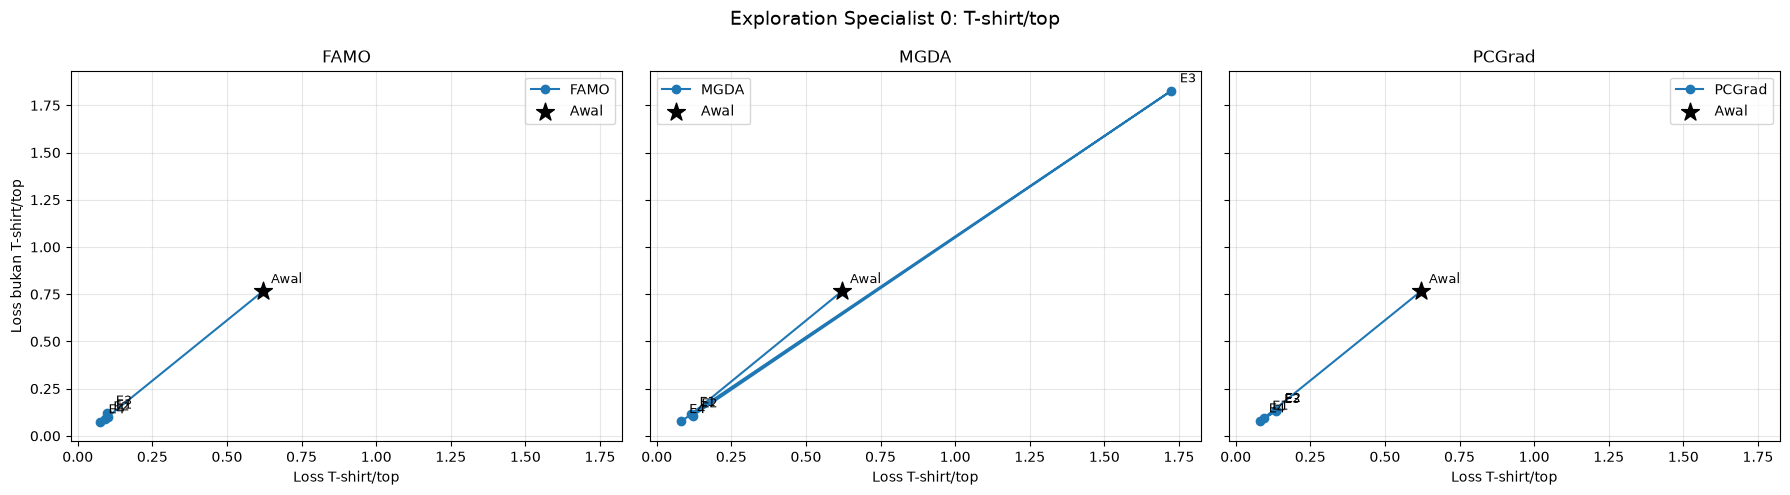

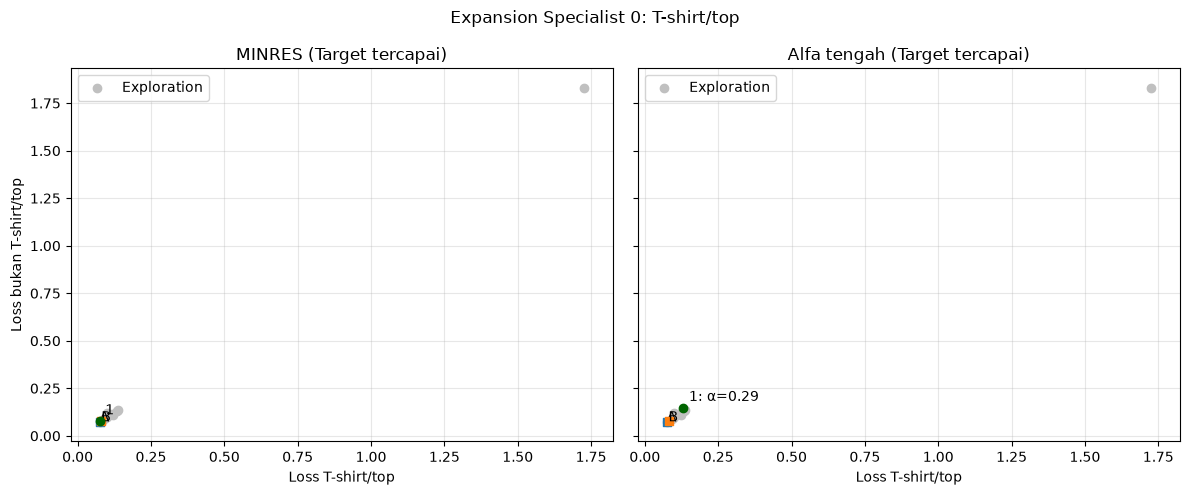

TERPILIH: FAMO | valid: [0.075  0.0754] | test: [0.0709 0.0711]

===== 1/9: Trouser =====


KeyboardInterrupt: 

In [33]:
# Sel training yang panjang: 10 kelas × 3 metode exploration × 2 metode expansion.
teachers = []
specialist_summaries = []
for class_id in range(len(CLASS_NAMES)):
    print(f"\n===== {class_id}/9: {CLASS_NAMES[class_id]} =====")
    teacher, summary = run_specialist_class(class_id)
    teachers.append(teacher)
    specialist_summaries.append(summary)
    print('TERPILIH:', summary['selected_method'],
          '| valid:', np.round(summary['selected_valid'], 4),
          '| test:', np.round(summary['selected_test'], 4))

assert len(teachers) == len(CLASS_NAMES)
print('Selesai: seluruh 10 teacher dibuat dari hasil Pareto Exploration/Expansion.')


In [ ]:
# Ringkasan compact, tanpa 10× seluruh state checkpoint di RAM.
print('Kelas | Teacher terpilih | valid X,Y | valid minimax | test X,Y | MINRES | Alfa tengah')
for s in specialist_summaries:
    m = s['expansion']['MINRES']
    a = s['expansion']['Alfa tengah']
    print(f"{s['class_name']:12} | {s['selected_method']:11} | "
          f"{np.round(s['selected_valid'], 4)} | {s['selected_score']:.4f} | "
          f"{np.round(s['selected_test'], 4)} | "
          f"{m['rounds']} ronde ({m['reason']}) | "
          f"{a['rounds']} ronde ({a['reason']})")


## Generalis: satu model untuk seluruh kelas
Setiap kelas punya dua keluaran: hadir dan tidak hadir. X adalah rata-rata loss hadir untuk sepuluh kelas, Y rata-rata loss tidak hadir. Kedua tujuan inilah yang diseimbangkan PCGrad, MGDA, dan FAMO. Generalis melihat gambar tumpukan utuh. Sepuluh guru memberikan target lunak dari potongan pakaian saat pelatihan. Validasi dan uji mengukur kesalahan terhadap label asli.

In [ ]:
class Generalist(Specialist):
    def __init__(self):
        super().__init__()
        # Satu backbone bersama; tiap lapisan menghasilkan dua skor untuk satu kelas.
        self.heads = nn.ModuleList(nn.Linear(32, 2) for _ in CLASS_NAMES)

    def forward(self, x):
        features = self.backbone(x)
        return torch.stack([head(features) for head in self.heads], dim=1)

In [ ]:
@torch.no_grad()
def teacher_targets(images, positions, teachers):
    # Satu guru menilai setiap crop yang terisi. Ambil peluang tertinggi antar-crop.
    target = torch.zeros(len(images), len(teachers))
    for slot in range(positions.shape[1]):
        rows = np.flatnonzero(positions[:, slot, 0] >= 0)
        crops = crop_pad(images, positions, slot)
        for start_row in range(0, len(rows), CFG['BS']):
            ids = rows[start_row:start_row + CFG['BS']]
            x = prep(torch.from_numpy(crops[ids]).to(dev))
            prob = torch.stack([t(x)[:, 0].sigmoid() for t in teachers], dim=1).cpu()
            target[ids] = torch.maximum(target[ids], prob)
    return target

In [ ]:
def generalist_data(images, labels, size, seed, teachers=None):
    # ID kelas tiap slot menjadi label hadir/tidak untuk evaluasi. Guru memberikan target latih.
    canvas, slots, positions = make_multi_flexible(images, labels, size, seed=seed)
    if teachers is None:
        target = torch.stack([torch.from_numpy((slots == c).any(axis=1))
                              for c in range(len(CLASS_NAMES))], dim=1).float()
    else:
        target = teacher_targets(canvas, positions, teachers)
    return torch.from_numpy(canvas), target

In [ ]:
gen_train = generalist_data(fa_tr_x, fa_tr_y, 20000, 1, teachers)
gen_valid = generalist_data(fa_val_x, fa_val_y, 2000, 2)
gen_test = generalist_data(fa_te_x, fa_te_y, 5000, 3)

In [ ]:
# Tiga metode mulai dari salinan generalis yang persis sama.
set_seed(CFG['SEED'])
gen_initial = Generalist().to(dev)
gen_start = checkpoint(gen_initial, 'Awal', valid=gen_valid)
gen_paths = {m: explore(gen_initial, m, gen_train, gen_valid) for m in ('PCGrad', 'MGDA', 'FAMO')}

In [ ]:
fig, ax = plt.subplots()
for method, points in gen_paths.items():
    xy = np.array([p['xy'] for p in [gen_start] + points])
    ax.plot(*xy.T, 'o-', label=method)
    ax.annotate(method, xy[-1])
ax.scatter(*gen_start['xy'], marker='*', s=140, color='black', label='Sebelum training')
ax.set(xlabel='Rata-rata loss hadir (10 kelas)', ylabel='Rata-rata loss tidak hadir (10 kelas)', title='Generalis: satu titik per epoch')
ax.legend()
plt.show()

In [ ]:
gen_pool = [p for path in gen_paths.values() for p in path]
gen_pair = choose_pair(gen_pool)
print('Pasangan generalis:', [p['name'] for p in gen_pair] if gen_pair else 'Tidak ada pasangan yang memenuhi syarat')

In [ ]:
gen_results = {'Tanpa expand': ([], 0., 'Baseline')}
for name, generate in [('MINRES', minres_candidate), ('Alfa tengah', midpoint_candidate)]:
    gen_results[name] = run_expand(gen_pair, generate, gen_initial, gen_pool, gen_train, gen_valid)

In [ ]:
fig, panels = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(panels, ('MINRES', 'Alfa tengah')):
    ax.scatter(*np.array([p['xy'] for p in gen_pool]).T, color='silver', label='Exploration awal')
    for label, point in zip(('A', 'B'), gen_pair or ()):
        ax.scatter(*point['xy'], marker='s')
        ax.annotate(label, point['xy'])
    for r, point in enumerate(gen_results[name][0], 1):
        ax.scatter(*point['xy'], color='darkgreen')
        label = str(r) if name == 'MINRES' else f"{r}: a={point['alpha'][0]:.2f}"
        ax.annotate(label, point['xy'])
    ax.set(title=name, xlabel='Rata-rata loss hadir (10 kelas)', ylabel='Rata-rata loss tidak hadir (10 kelas)')
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Pilih model memakai validasi saja. Tampilkan dua loss uji setelah pemilihan selesai.
print('Kondisi | ronde | detik expand | validasi X,Y | skor validasi | uji X,Y | alasan berhenti')
for name, (extra, seconds, reason) in gen_results.items():
    winner = min(gen_pool + extra, key=lambda p: p['score'])
    model = deepcopy(gen_initial)
    model.load_state_dict(winner['state'])
    print(name, len(extra), round(seconds, 2), winner['xy'].round(4),
          round(winner['score'], 4), evaluate(model, gen_test).round(4), reason, sep=' | ')

## Catatan komputasi dan interpretasi

- **Semua teacher** dibuat menggunakan exploration PCGrad/MGDA/FAMO dan upaya expansion MINRES/Alfa tengah; kandidat akhir selalu dipilih berdasarkan validasi. Jika solver gagal atau tidak ada pasangan yang memadai, catatan `specialist_summaries[*]['expansion']` menjelaskan alasannya, dan teacher menggunakan kandidat terbaik yang berhasil tersedia.
- `MINRES_BS=8` membatasi ukuran batch pada HVP tetapi bukan mengubah jumlah parameter Hessian; tetap sangat mahal di ResNet-18. Parameter `SECONDS` tidak dapat memotong solver MINRES di tengah proses.
- Dengan fallback, pasangan belum tentu benar-benar Pareto optimal; tidak boleh menyebut seluruh checkpoint/hasil sebagai *Pareto front* tanpa uji dominasi.
- Sepuluh teacher dibiarkan di perangkat `dev` dalam mode `.eval()` dan `requires_grad=False` untuk mempercepat pembuatan target generalist; memerlukan tambahan VRAM. Untuk memulihkan teacher dari disk, buat `Specialist()` baru dan `load_state_dict(torch.load(..., map_location=dev, weights_only=True)['state_dict'])` kemudian `.eval()`.
- Menyimpan checkpoint yang terpilih **bukan** menyimpan optimizer dan state training; cocok untuk inference/target teacher, bukan melanjutkan training identik.